# Refit against the published map

The refit trains one random forest per HUC-2 watershed with `train_fdp.R`, a port of the
released R script of Collins et al. (2022), on the points in [Training points](training-points.ipynb).
This notebook checks three things: that the port reproduces the published surface, how the
served run compares with it in every watershed, and how much of the map moves with the
random draws as against the added years.

Code: `input-data/tensor/fdp/fdp_train.py` and `train_fdp.R`. Each watershed's `summary.json`
(cross-validation, tuned parameters) and `compare.json` (agreement with the published
surface over the same cells, and separately outside the 100-year floodplain) are under
`s3://carbonplan-ocr/input/flood/fdp-refit/runs/<run>/<distance>/huc<NN>/`.

The 100-year floodplain has no pseudo-absences, so every forest scores it near 1 and both
surfaces agree there trivially. The figures outside the floodplain are the informative ones.

In [1]:
import json

import fsspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio.windows import from_bounds

REFIT = 's3://carbonplan-ocr/input/flood/fdp-refit'
RUN = 'noaa-200612-202512'
HUCS = [f'{i:02d}' for i in range(1, 19)]
NAMES = {
    '01': 'New England',
    '02': 'Mid Atlantic',
    '03': 'South Atlantic-Gulf',
    '04': 'Great Lakes',
    '05': 'Ohio',
    '06': 'Tennessee',
    '07': 'Upper Mississippi',
    '08': 'Lower Mississippi',
    '09': 'Souris-Red-Rainy',
    '10': 'Missouri',
    '11': 'Arkansas-White-Red',
    '12': 'Texas-Gulf',
    '13': 'Rio Grande',
    '14': 'Upper Colorado',
    '15': 'Lower Colorado',
    '16': 'Great Basin',
    '17': 'Pacific Northwest',
    '18': 'California',
}
fs = fsspec.filesystem('s3')


def record(path):
    return json.loads(fs.cat_file(f'{REFIT}/{path}'))


BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#9aa5b1'
plt.rcParams.update(
    {'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110, 'font.size': 9}
)
pd.set_option('display.max_rows', 40)


def run_records(run, distance, huc):
    path = f'runs/{run}/{distance}/huc{huc}'
    return record(f'{path}/summary.json'), record(f'{path}/compare.json')


def agreement(run, distance, huc):
    s, c = run_records(run, distance, huc)
    out = c['outside_floodplain']
    return {
        'CV AUC': np.mean(s['cv']['auc']),
        'r': c['pearson'],
        'r outside floodplain': out['pearson'],
        'top-20% overlap outside floodplain': out['top20_overlap'],
        'mean |difference|': c['abs_diff']['mean'],
    }

## 1. The port reproduces the published surface

Trained on the released points, the port's surface correlates with the published one at
r = 0.986 in HUC 03 and 0.956 in HUC 06. Exact agreement isn't expected: the released script
seeds neither its folds nor its tuning.

The released script measures the distances it uses to keep test points away from training
points (dismo's `pwdSample`) as if the Albers metre coordinates were degrees, so its
cross-validation folds are effectively random. `--distance lonlat` keeps that; `--distance
planar` measures true distances. In both watersheds the two settings give the same map, but
the CV AUC with true distances is lower, by 0.07 in HUC 03 and 0.06 in HUC 06: the released
script's AUCs, like the paper's 0.750, are measured on test points that sit close to their
training points.

In [2]:
port = pd.DataFrame(
    {
        (huc, distance): agreement('original', distance, huc)
        for huc in ('03', '06')
        for distance in ('lonlat', 'planar')
    }
).T
port.index.names = ['HUC', 'distance']
port.style.format('{:.3f}')

## 2. The served run, by watershed

The served run (`noaa-200612-202512`, planar distances) adds June 2020–December 2025 to the
points. Its CV AUC runs from 0.62 in Souris-Red-Rainy and Great Basin, the two smallest
watersheds, to 0.73 in Lower Mississippi. Agreement with the published surface outside the
floodplain tracks how many points a watershed has: r = 0.82–0.94 where there are at least
5,000 presences, 0.67–0.87 where there are fewer.

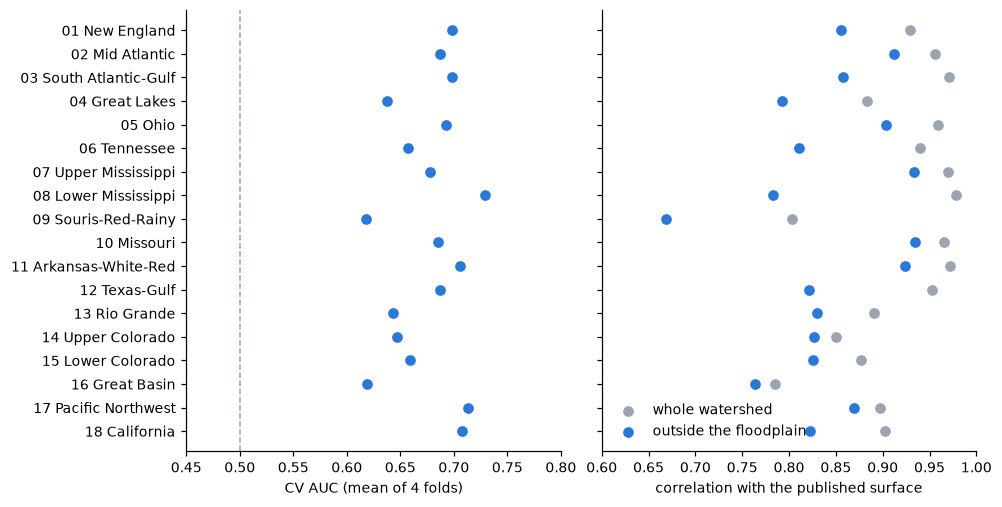

,presences,floodplain share,CV AUC,r,r outside floodplain,top-20% overlap outside floodplain,mean |difference|,mtry,min.node.size,sample.fraction
HUC,,,,,,,,,,
01 New England,"3,562",0.070,0.698,0.929,0.856,0.724,0.064,10,9,0.270
02 Mid Atlantic,"13,696",0.074,0.688,0.956,0.912,0.777,0.052,5,22,0.488
03 South Atlantic-Gulf,"12,029",0.199,0.699,0.971,0.857,0.698,0.046,4,14,0.513
04 Great Lakes,"2,729",0.066,0.637,0.884,0.792,0.626,0.063,2,3,0.470
05 Ohio,"15,711",0.077,0.693,0.959,0.903,0.771,0.045,6,60,0.493
06 Tennessee,"2,709",0.068,0.658,0.940,0.810,0.689,0.047,11,42,0.352
07 Upper Mississippi,"7,885",0.101,0.678,0.970,0.933,0.739,0.044,4,35,0.682
08 Lower Mississippi,"4,900",0.352,0.729,0.978,0.783,0.584,0.040,11,102,0.473
09 Souris-Red-Rainy,548,0.081,0.618,0.803,0.669,0.559,0.080,2,2,0.413


In [3]:
rows = []
for huc in HUCS:
    s, c = run_records(RUN, 'planar', huc)
    rows.append(
        {
            'HUC': f'{huc} {NAMES[huc]}',
            'presences': s['points']['presence'],
            'floodplain share': c['floodplain_share'],
            **agreement(RUN, 'planar', huc),
            'mtry': s['final']['mtry'],
            'min.node.size': s['final']['min_node_size'],
            'sample.fraction': s['final']['sample_fraction'],
        }
    )
served = pd.DataFrame(rows).set_index('HUC')
fig, (a, b) = plt.subplots(1, 2, figsize=(9, 4.5), sharey=True, layout='constrained')
y = np.arange(len(served))
a.scatter(served['CV AUC'], y, color=BLUE)
a.axvline(0.5, color=GRAY, linestyle='--', linewidth=1)
a.set(xlabel='CV AUC (mean of 4 folds)', yticks=y, yticklabels=served.index, xlim=(0.45, 0.8))
b.scatter(served['r'], y, color=GRAY, label='whole watershed')
b.scatter(served['r outside floodplain'], y, color=BLUE, label='outside the floodplain')
b.set(xlabel='correlation with the published surface', xlim=(0.6, 1))
b.legend(frameon=False, loc='lower left')
a.invert_yaxis()
plt.show()
served.style.format({'presences': '{:,}', 'mtry': '{:d}', 'min.node.size': '{:d}'}, precision=3)

In [4]:
print(f'CV AUC: {served["CV AUC"].min():.3f} to {served["CV AUC"].max():.3f}')
big = served['presences'] >= 5000
print(
    f'r outside the floodplain, watersheds with ≥5,000 presences: '
    f'{served.loc[big, "r outside floodplain"].min():.3f} to {served.loc[big, "r outside floodplain"].max():.3f}; '
    f'with fewer: {served.loc[~big, "r outside floodplain"].min():.3f} to {served.loc[~big, "r outside floodplain"].max():.3f}'
)
print(
    'Spearman, presences vs r outside the floodplain:',
    round(served['presences'].corr(served['r outside floodplain'], method='spearman'), 2),
)

CV AUC: 0.618 to 0.729
r outside the floodplain, watersheds with ≥5,000 presences: 0.821 to 0.935; with fewer: 0.669 to 0.869


Spearman, presences vs r outside the floodplain: 0.66


## 3. What moves the map

In HUC 03 the served run was repeated with four other seeds, which redraw the pseudo-absences
and the folds, and once with the points ending in May 2020. Comparing these surfaces cell by
cell, outside the floodplain, separates the map's sensitivity to the random draws from its
response to the added years.

Two seeds differ by 0.047–0.052 per cell on average, and six more years of reports move the
map by 0.060, not much more. The surface trained to May 2020 sits closer to the published
one (0.048) than any surface trained to December 2025 does (0.053–0.057).

In [5]:
HUC = '03'
SURFACES = {
    'served': f'runs/{RUN}/planar',
    **{f'seed {i}': f'runs/{RUN}-seed{i}/planar' for i in range(1, 5)},
    'to May 2020': 'runs/noaa-200612-202005/planar',
}
with rasterio.open(f'{REFIT}/{SURFACES["served"]}/huc{HUC}/fdp.tif') as src:
    bounds, nodata = src.bounds, src.nodata
    valid = src.read(1) != nodata
with rasterio.open(f'{REFIT}/inputs/predictors/floodplain.tif') as src:
    floodplain = src.read(1, window=from_bounds(*bounds, src.transform))
keep = valid & (floodplain != 1)
maps = {}
for name, path in SURFACES.items():
    with rasterio.open(f'{REFIT}/{path}/huc{HUC}/fdp.tif') as src:
        maps[name] = src.read(1)[keep]
with rasterio.open('s3://carbonplan-ocr/input/flood/raw/usgs-fdp/CONUS_FDP_100m.tif') as src:
    maps['published'] = src.read(1, window=from_bounds(*bounds, src.transform))[keep]
    assert (maps['published'] != src.nodata).all()
print(f'HUC {HUC} cells outside the floodplain: {keep.sum():,} of {valid.sum():,}')

HUC 03 cells outside the floodplain: 54,094,434 of 67,569,911


In [6]:
names = list(maps)
mad = pd.DataFrame(index=names, columns=names, dtype=float)
for i, x in enumerate(names):
    for z in names[i:]:
        mad.loc[x, z] = mad.loc[z, x] = np.abs(maps[x] - maps[z]).mean()
mad.style.format('{:.3f}').background_gradient(cmap='Blues', axis=None)

,served,seed 1,seed 2,seed 3,seed 4,to May 2020,published
served,0.000,0.052,0.047,0.052,0.050,0.060,0.056
seed 1,0.052,0.000,0.051,0.052,0.052,0.063,0.057
seed 2,0.047,0.051,0.000,0.049,0.047,0.061,0.053
seed 3,0.052,0.052,0.049,0.000,0.050,0.064,0.055
seed 4,0.050,0.052,0.047,0.050,0.000,0.062,0.056
to May 2020,0.060,0.063,0.061,0.064,0.062,0.000,0.048
published,0.056,0.057,0.053,0.055,0.056,0.048,0.000


In [7]:
seeds = ['served'] + [f'seed {i}' for i in range(1, 5)]
pairs = [mad.loc[x, z] for i, x in enumerate(seeds) for z in seeds[i + 1 :]]
print(f'mean |difference| between seeds:            {min(pairs):.3f} to {max(pairs):.3f}')
print(f'served vs to May 2020 (six more years):      {mad.loc["served", "to May 2020"]:.3f}')
print(f'to May 2020 vs the published surface:        {mad.loc["to May 2020", "published"]:.3f}')
print(
    f'seeds vs the published surface:              {mad.loc[seeds, "published"].min():.3f} to {mad.loc[seeds, "published"].max():.3f}'
)

mean |difference| between seeds:            0.047 to 0.052
served vs to May 2020 (six more years):      0.060
to May 2020 vs the published surface:        0.048
seeds vs the published surface:              0.053 to 0.057
